# Задача 3.15. Диффузия радиоактивного изотопа

## Постановка

Газ поступает в прямоугольную изолированную камеру через движущуюся форсунку. Требуется построить распределение концентрации в различные моменты времени.

$$
\begin{cases}
\displaystyle \frac{\partial u}{\partial t}=D\Delta u-\beta u+f(x,y,t), & (x,y)\in\Omega,\ t>0,\\[4pt]
\displaystyle \frac{\partial u}{\partial n}\bigg|_{\partial\Omega}=0, & u(x,y,0)=0.
\end{cases}
$$

Положение форсунки:

$$
x_s(t)=\frac{a\cos(\omega t)}{1+\sin^2(\omega t)},\qquad
y_s(t)=\frac{a\sin(\omega t)\cos(\omega t)}{1+\sin^2(\omega t)}.
$$

Точечный источник:

$f(x, y, t) = Q\delta(x-x_s)\delta(y-y_s)$

Здесь $D$ — коэффициент диффузии, $\beta$ — коэффициент распада, $Q$ — интенсивность подачи изотопа.


In [ ]:
import numpy as np

In [ ]:
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.linalg import splu

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [ ]:
def make_grid(x_min, x_max, y_min, y_max, nx, ny):
    hx = (x_max - x_min) / nx
    hy = (y_max - y_min) / ny

    x = x_min + (np.arange(nx) + 0.5) * hx
    y = y_min + (np.arange(ny) + 0.5) * hy

    X, Y = np.meshgrid(x, y, indexing='ij')
    return X, Y, hx, hy

## Источник и траектория

In [ ]:
def nozzle_position(t, a, omega):
    s = np.sin(omega * t)
    c = np.cos(omega * t)
    return a * c / (1.0 + s**2), a * s * c / (1.0 + s**2)

In [ ]:
def RHS(X, Y, hx, hy, t, a, omega, Q, sigma):
    x0, y0 = nozzle_position(t, a, omega)
    kernel = np.exp(-((X - x0)**2 + (Y - y0)**2) / (2.0 * sigma**2))
    return Q * kernel / (hx * hy * kernel.sum())


## Разреженная матрица оператора

Рассмотрим уравнение диффузии с радиоактивным распадом:

$$
\frac{\partial u}{\partial t}+ \mathcal{L}u=f(x,y,t),
\qquad
\mathcal{L}u=-D\Delta u+\beta u.
$$

Построим конечно-объёмную аппроксимацию оператора $\mathcal{L}$ на равномерной прямоугольной сетке. Обозначим сеточный оператор через $L$:

$$
\begin{aligned}
(Lu)_{ij}={}&
D\left(
[i>0]\frac{u_{ij}-u_{i-1,j}}{h_x^2}
+[i<n_x-1]\frac{u_{ij}-u_{i+1,j}}{h_x^2}
\right.\\
&\left.
+[j>0]\frac{u_{ij}-u_{i,j-1}}{h_y^2}
+[j<n_y-1]\frac{u_{ij}-u_{i,j+1}}{h_y^2}
\right)+\beta u_{ij}.
\end{aligned}
$$

Квадратные скобки обозначают индикаторы выполнения условий. На границах области отсутствуют внешние потоки (однородные условия Неймана).

Временной шаг обозначим $\tau$, номер временного слоя — $k$.

Схема с весами:

$$
\frac{u^{k+1}-u^k}{\tau}
+(1-\nu)Lu^k+\nu Lu^{k+1}
=F(t_k+\nu\tau),
\qquad \nu\in[0,1].
$$

При $\nu=0$ получаем явную схему, при $\nu=1$ — полностью неявную, а при $\nu=1/2$ — схему Кранка — Николсон.

Перепишем уравнение в виде СЛАУ:

$$
Au^{k+1}=Bu^k+\tau F(t_k+\nu\tau),
$$

где

$$
\boxed{
A=I+\tau\nu L,\qquad
B=I-\tau(1-\nu)L.
}
$$


In [ ]:
def OpL_sparse(nx, ny, hx, hy, alpha=0.0):
    index = np.arange(nx * ny).reshape(nx, ny)
    left, right = index[:-1, :].ravel(), index[1:, :].ravel()
    bottom, top = index[:, :-1].ravel(), index[:, 1:].ravel()

    row = np.concatenate((left, right, bottom, top))
    col = np.concatenate((right, left, top, bottom))
    values = np.concatenate((
        np.full(left.size + right.size, -1.0 / hx**2),
        np.full(bottom.size + top.size, -1.0 / hy**2),
    ))
    diagonal = alpha - np.bincount(row, weights=values, minlength=nx * ny)
    p = np.arange(nx * ny)
    return sp.csr_matrix(
        (np.r_[diagonal, values], (np.r_[p, row], np.r_[p, col])),
        shape=(nx * ny, nx * ny),
    )

## Решение на временной сетке

In [ ]:
def build_system(nx, ny, hx, hy, D, beta, tau, nu):
    if not 0 <= nu <= 1:
        raise ValueError("nu должно принадлежать [0, 1]")

    I = sp.eye(nx * ny, format="csr")
    L = D * OpL_sparse(nx, ny, hx, hy) + beta * I

    A = I + tau * nu * L
    B = I - tau * (1 - nu) * L

    return A, B

In [ ]:
def make_solver(A, method="lu", tol=1e-8, preconditioner=None):
    stats = {"iterations": 0, "calls": 0}

    if method == "lu":
        lu = splu(A.tocsc())

        def solve(b, x0=None):
            stats["calls"] += 1
            return lu.solve(b)

    elif method == "cg":
        M = None

        if preconditioner == "jacobi":
            D_inv = 1.0 / A.diagonal()
            M = spla.LinearOperator(
                A.shape, matvec=lambda r: D_inv * r
            )

        elif preconditioner == "ssor":
            D = A.diagonal()
            L = sp.tril(A, k=-1, format="csr")
            lower = (sp.diags(D) + L).tocsr()
            upper = lower.T.tocsr()

            def apply_ssor(r):
                y = spla.spsolve_triangular(lower, r, lower=True)
                return spla.spsolve_triangular(
                    upper, D * y, lower=False
                )

            M = spla.LinearOperator(A.shape, matvec=apply_ssor)

        elif preconditioner == "ilu":
            ilu = spla.spilu(
                A.tocsc(), drop_tol=1e-3, fill_factor=5
            )
            M = spla.LinearOperator(A.shape, matvec=ilu.solve)

        elif preconditioner is not None:
            raise ValueError(f"Неизвестный предобуславливатель: {preconditioner}")

        if method == "cg" and preconditioner == "ilu":
            raise ValueError("ILU не гарантирует SPD: используйте bicgstab")

        iterative_solver = spla.cg if method == "cg" else spla.bicgstab

        def solve(b, x0=None):
            n_iter = 0

            def callback(xk):
                nonlocal n_iter
                n_iter += 1

            x, info = iterative_solver(
                A, b, x0=x0,
                rtol=tol, atol=0.0,
                M=M,
                callback=callback
            )

            if info != 0:
                raise RuntimeError(f"{method} не сошёлся: info={info}")

            stats["calls"] += 1
            stats["iterations"] += n_iter
            return x

    else:
        raise ValueError(f"Неизвестный метод: {method}")

    return solve, stats

In [ ]:
def integrate(A, B, solver, X, Y, hx, hy,
              a, omega, Q, sigma, tau, nu, steps):

    nx, ny = X.shape
    u = np.zeros(nx * ny)

    yield 0.0, u.reshape(nx, ny)

    for k in range(steps):
        t_source = (k + nu) * tau
        F = RHS(X, Y, hx, hy, t_source, a, omega, Q, sigma)

        b = B @ u + tau * F.ravel()
        u = solver(b, x0=u)

        yield (k + 1) * tau, u.reshape(nx, ny)

In [ ]:
def collect_results(trajectory, hx, hy, snapshot_every, steps):
    times, snapshots, masses = [], [], []
    mass_times, mass_history = [], []
    u_final = None

    for k, (t, u) in enumerate(trajectory):
        mass = u.sum() * hx * hy

        mass_times.append(t)
        mass_history.append(mass)

        if k % snapshot_every == 0 or k == steps:
            times.append(t)
            snapshots.append(u.copy())
            masses.append(mass)

        u_final = u

    return dict(
        u=u_final.copy(),
        times=np.array(times),
        snapshots=snapshots,
        masses=np.array(masses),
        mass_times=np.array(mass_times),
        mass_history=np.array(mass_history)
    )

In [ ]:
def solve_sparse(nx=80, ny=80, L=1.5, a=1.0, omega=1.0,
                 D=0.04, beta=0.2, Q=1.0, sigma=None,
                 tau=0.025, nu=0.5, t_end=12.0,
                 snapshot_every=20, method="lu", tol=1e-8):
    X, Y, hx, hy = make_grid(-L, L, -L, L, nx, ny)

    if sigma is None:
        sigma = 1.5 * max(hx, hy)

    steps = int(np.ceil(t_end / tau))
    tau = t_end / steps

    A, B = build_system(nx, ny, hx, hy, D, beta, tau, nu)
    solver, stats = make_solver(A, method=method, tol=tol)

    trajectory = integrate(
        A, B, solver, X, Y, hx, hy,
        a, omega, Q, sigma, tau, nu, steps
    )

    result = collect_results(
        trajectory, hx, hy, snapshot_every, steps
    )

    result.update(
        X=X, Y=Y, hx=hx, hy=hy,
        A=A, B=B, steps=steps,
        params=dict(
            nx=nx, ny=ny, L=L, a=a, omega=omega,
            D=D, beta=beta, Q=Q, sigma=sigma,
            tau=tau, nu=nu, t_end=t_end,
            method=method, tol=tol
        )
    )
    result["solver_stats"] = stats.copy()

    return result

## Визуализация

In [ ]:
def plot_trajectory(params):
    t = np.linspace(0, 2 * np.pi / params['omega'], 600)
    xs, ys = nozzle_position(t, params['a'], params['omega'])
    fig, ax = plt.subplots(figsize=(6, 5), dpi=90)
    ax.plot(xs, ys, color='black')
    ax.plot(xs[0], ys[0], 'ro', label='Начало')
    L = params['L']
    ax.set(xlim=(-L, L), ylim=(-L, L), xlabel='x', ylabel='y',
           title='Траектория форсунки')
    ax.set_aspect('equal'); ax.grid(ls=':', alpha=0.4); ax.legend()
    plt.tight_layout(); plt.show()

In [ ]:
def plot_solution(res, indices=None):
    frames = res['snapshots']
    times = res['times']
    if indices is None:
        indices = np.unique(np.linspace(0, len(frames) - 1, 4, dtype=int))
    vmax = max(frame.max() for frame in frames)
    fig, axes = plt.subplots(1, len(indices), figsize=(4 * len(indices), 4),
                             dpi=90, constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, indices):
        m = ax.pcolormesh(res['X'], res['Y'], frames[i],
                          shading='nearest', cmap='viridis', vmin=0, vmax=vmax)
        x0, y0 = nozzle_position(times[i], res['params']['a'], res['params']['omega'])
        ax.plot(x0, y0, 'rx', ms=7)
        ax.set_title(f't = {times[i]:.2f}')
        ax.set_aspect('equal'); ax.set_xlabel('x'); ax.set_ylabel('y')
    fig.colorbar(m, ax=axes, shrink=0.78, label='Концентрация u')
    plt.show()

In [ ]:
def plot_mass(res):
    p = res['params']
    t = res['mass_times']
    if p['beta'] > 0:
        exact = p['Q'] / p['beta'] * (1.0 - np.exp(-p['beta'] * t))
    else:
        exact = p['Q'] * t
    fig, ax = plt.subplots(figsize=(7, 4), dpi=90)
    ax.plot(t, res['mass_history'], label='Численная масса')
    ax.plot(t, exact, '--', color='black', label='Точный баланс массы')
    ax.set(xlabel='Время t', ylabel=r'$M(t)=\int_\Omega u\,dx\,dy$',
           title='Контроль баланса изотопа')
    ax.grid(ls=':', alpha=0.5); ax.legend()
    plt.tight_layout(); plt.show()
    print(f"Максимальная ошибка массы: {np.max(np.abs(res['mass_history']-exact)):.3e}")

In [ ]:
def animate_solution(res, interval=120, vmax=None, gamma=0.5):
    frames = res['snapshots']
    times = res['times']
    p = res['params']

    if vmax is None:
        vmax = max(frame.max() for frame in frames)

    fig, ax = plt.subplots(figsize=(6, 5), dpi=90)

    im = ax.pcolormesh(
        res['X'], res['Y'], frames[0],
        shading='nearest',
        cmap='viridis',
        norm=PowerNorm(gamma=gamma, vmin=0, vmax=max(vmax, 1e-12))
    )

    fig.colorbar(im, ax=ax, label='Концентрация u')
    marker, = ax.plot([], [], 'rx', ms=8)
    ax.set_aspect('equal')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

    def update(i):
        im.set_array(frames[i].ravel())
        x0, y0 = nozzle_position(times[i], p['a'], p['omega'])
        marker.set_data([x0], [y0])
        ax.set_title(f'Концентрация, t = {times[i]:.2f}')
        return im, marker

    animation = FuncAnimation(
        fig, update, frames=len(frames),
        interval=interval, blit=False, repeat=False
    )
    plt.close(fig)
    return HTML(animation.to_jshtml())


## Численный эксперимент

In [ ]:
params = dict(
    nx=80, ny=80, L=1.5, a=1.0, omega=1.0,
    D=0.04, beta=0.2, Q=10.0,
    tau=0.025, nu=0.5,
    t_end=15.0, snapshot_every=20
)
res = solve_sparse(**params)

A = res['A']
print(f"Матрица: {A.shape}, формат {A.format}, ненулевых элементов {A.nnz}")
print(f"Шагов по времени: {res['steps']}")
print(f"Метод решения: {res['params']['method']}")
print(f"Концентрация max: {res['u'].max():.5f}")

Матрица: (6400, 6400), формат csr, ненулевых элементов 31680
Шагов по времени: 600
Метод решения: lu
Концентрация max: 46.11511


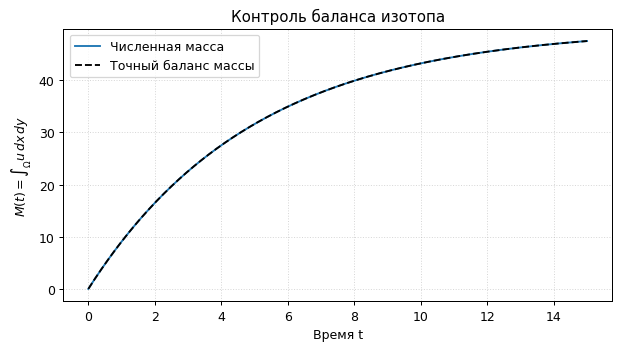

Максимальная ошибка массы: 3.832e-05


In [ ]:
plot_mass(res)

## Анимация по времени

In [ ]:
animate_solution(res)

## Сравнение

In [ ]:
from time import perf_counter

benchmark = []

for n in (40, 80, 160, 320):
    results = {}

    for method in ("lu", "cg"):
        start = perf_counter()
        res = solve_sparse(**{**params, "nx": n, "ny": n, "method": method})
        elapsed = perf_counter() - start

        results[method] = res
        stats = res["solver_stats"]

        benchmark.append((n, method, elapsed,
                          stats["iterations"] / stats["calls"] if method == "cg" else 0))

    u_lu, u_cg = results["lu"]["u"], results["cg"]["u"]
    rel_error = np.linalg.norm(u_lu - u_cg) / np.linalg.norm(u_lu)

    print(f"{n}x{n}:")
    for size, method, elapsed, iterations in benchmark[-2:]:
        print(f"  {method.upper()}: {elapsed:.3f} с"
              + (f", {iterations:.1f} итераций/шаг" if method == "cg" else ""))
    print(f"  Относительное отличие: {rel_error:.3e}")

40x40:
  LU: 0.251 с
  CG: 0.263 с, 6.0 итераций/шаг
  Относительное отличие: 2.487e-08
80x80:
  LU: 0.825 с
  CG: 0.859 с, 11.6 итераций/шаг
  Относительное отличие: 5.730e-08
160x160:
  LU: 5.955 с
  CG: 7.496 с, 26.0 итераций/шаг
  Относительное отличие: 3.531e-08
320x320:
  LU: 24.500 с
  CG: 74.084 с, 57.0 итераций/шаг
  Относительное отличие: 2.588e-08
